ANALYSIS OF PREMIER LEAGUE MATCH OUTCOMES

2026297, Erick Henrique da Silva, 

Github Link: https://github.com/2026297-cyber/Statistical-Techniques
Datasets: https://datahub.io/football/english-premier-league

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import scipy.stats as stats
from scipy.stats import binom, poisson

In [3]:
df1  = pd.read_csv("season-2526.csv")
df2  = pd.read_csv("season-2425.csv")
df3  = pd.read_csv("season-2324.csv")
df4  = pd.read_csv("season-2223.csv")
df5  = pd.read_csv("season-2122.csv")
df6  = pd.read_csv("season-2021.csv")
df7  = pd.read_csv("season-1920.csv")
df8  = pd.read_csv("season-1819.csv")
df9  = pd.read_csv("season-1718.csv")
df10 = pd.read_csv("season-1617.csv")

df = pd.concat([df1, df2, df3, df4, df5, df6, df7, df8, df9, df10], ignore_index=True)

In [4]:
   # --- DICTIONARY ---
# FTHG = Full Time Home Goals 
# FTAG = Full Time Away Goals 
# FTR  = Full Time Result - (Home = H, Away = A, Draw = D)
# HTHG = Half Time Home Goals 
# HTAG = Half Time Away Goals 
# HTR  = Half Time Result 
# Referee = Match Referee
# HS   = Home Shots 
# AS   = Away Shots 
# HST  = Home Shots on Target 
# AST  = Away Shots on Target 
# HF   = Home Fouls 
# AF   = Away Fouls 
# HC   = Home Corners 
# AC   = Away Corners 
# HY   = Home Yellows 
# AY   = Away Yellows 
# HR   = Home Reds 
# AR   = Away Reds

---------------------------------------------------------------------------------  PART 1  ------------------------------------------------------------------------------------

In [5]:
df.shape #Total of rows and columns. (In other words: total number of matches = 3800; 22 columns of different info)

(3800, 22)

In [6]:
df.info() #Number of Columns, Name and Type

<class 'pandas.DataFrame'>
RangeIndex: 3800 entries, 0 to 3799
Data columns (total 22 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   Date      3800 non-null   str  
 1   HomeTeam  3800 non-null   str  
 2   AwayTeam  3800 non-null   str  
 3   FTHG      3800 non-null   int64
 4   FTAG      3800 non-null   int64
 5   FTR       3800 non-null   str  
 6   HTHG      3800 non-null   int64
 7   HTAG      3800 non-null   int64
 8   HTR       3800 non-null   str  
 9   Referee   3800 non-null   str  
 10  HS        3800 non-null   int64
 11  AS        3800 non-null   int64
 12  HST       3800 non-null   int64
 13  AST       3800 non-null   int64
 14  HF        3800 non-null   int64
 15  AF        3800 non-null   int64
 16  HC        3800 non-null   int64
 17  AC        3800 non-null   int64
 18  HY        3800 non-null   int64
 19  AY        3800 non-null   int64
 20  HR        3800 non-null   int64
 21  AR        3800 non-null   int64
dtypes: int64(16

In [7]:
df.isnull().sum() #Check if there are any null values to dropna.

Date        0
HomeTeam    0
AwayTeam    0
FTHG        0
FTAG        0
FTR         0
HTHG        0
HTAG        0
HTR         0
Referee     0
HS          0
AS          0
HST         0
AST         0
HF          0
AF          0
HC          0
AC          0
HY          0
AY          0
HR          0
AR          0
dtype: int64

In [8]:
df.head() #First rows and columns to see how the data looks like

,Date,HomeTeam,AwayTeam,FTHG,FTAG,FTR,HTHG,HTAG,HTR,Referee,...,HST,AST,HF,AF,HC,AC,HY,AY,HR,AR
0,2025-08-15,Liverpool,Bournemouth,4,2,H,1,0,H,A Taylor,...,10,3,7,10,6,7,1,2,0,0
1,2025-08-16,Aston Villa,Newcastle,0,0,D,0,0,D,C Pawson,...,3,3,13,11,3,6,1,1,1,0
2,2025-08-16,Brighton,Fulham,1,1,D,0,0,D,S Barrott,...,4,2,16,15,4,3,3,3,0,0
3,2025-08-16,Sunderland,West Ham,3,0,H,0,0,D,R Jones,...,5,4,8,10,5,7,0,1,0,0
4,2025-08-16,Tottenham,Burnley,3,0,H,1,0,H,M Oliver,...,6,4,14,8,6,5,0,0,0,0


In [9]:
df[['Date', 'HomeTeam',	'AwayTeam',	'FTHG',	'FTAG', 'FTR']].head() #Check what columns see

,Date,HomeTeam,AwayTeam,FTHG,FTAG,FTR
0,2025-08-15,Liverpool,Bournemouth,4,2,H
1,2025-08-16,Aston Villa,Newcastle,0,0,D
2,2025-08-16,Brighton,Fulham,1,1,D
3,2025-08-16,Sunderland,West Ham,3,0,H
4,2025-08-16,Tottenham,Burnley,3,0,H


In [10]:
df.describe().T.round(2) # To check relevant datas (this command is better than just df.describe() because it is easier to read)

,count,mean,std,min,25%,50%,75%,max
FTHG,3800.0,1.56,1.31,0.0,1.0,1.0,2.0,9.0
FTAG,3800.0,1.28,1.21,0.0,0.0,1.0,2.0,9.0
HTHG,3800.0,0.70,0.85,0.0,0.0,0.0,1.0,5.0
HTAG,3800.0,0.56,0.78,0.0,0.0,0.0,1.0,5.0
HS,3800.0,13.87,5.69,0.0,10.0,13.0,17.0,37.0
AS,3800.0,11.48,5.06,0.0,8.0,11.0,15.0,37.0
HST,3800.0,4.77,2.62,0.0,3.0,4.0,6.0,17.0
AST,3800.0,4.02,2.36,0.0,2.0,4.0,5.0,15.0
HF,3800.0,10.60,3.43,0.0,8.0,10.0,13.0,24.0
AF,3800.0,10.87,3.56,1.0,8.0,11.0,13.0,26.0


- Home teams score more goals (1.56 X 1.28), more shots (13.87 X 11.48), more shots on target (4.77 X 4.02) and more corners (5.66 X 4.69). Away teams use to receive more yellow card (1.85 X 1.66).
- Checking Mean and median: values are close for majority variables, so the distribution is like symmetric. For goals, shots and corners the mean is a bit higher than the median, so the chart probably will have a short tail to the right.
- The numerical variables are whole number counts (discrete), so it can be analysed with Binomial and Poisson distributions in Part 2.

In [11]:
df['HomeTeam'].unique() #Teams that played in the Premier League in the last 10 years

<ArrowStringArray>
[       'Liverpool',      'Aston Villa',         'Brighton',
       'Sunderland',        'Tottenham',           'Wolves',
          'Chelsea',    'Nott'm Forest',       'Man United',
            'Leeds',         'West Ham',         'Man City',
      'Bournemouth',        'Brentford',          'Burnley',
          'Arsenal',   'Crystal Palace',          'Everton',
           'Fulham',        'Newcastle',          'Ipswich',
        'Leicester',      'Southampton', 'Sheffield United',
            'Luton',          'Watford',          'Norwich',
        'West Brom',     'Huddersfield',          'Cardiff',
            'Stoke',          'Swansea',             'Hull',
    'Middlesbrough']
Length: 34, dtype: str

In [12]:
print(df[['HomeTeam', 'AwayTeam', 'Referee']].nunique()) # To check how many teams played and referees.

HomeTeam    34
AwayTeam    34
Referee     50
dtype: int64


- Too many different teams, referee and categories to be analysed, so chart of teams or referees would not be easy to read, so analysis will focus in FTR and in the various numberical variables

In [13]:
#Check mean, median and mode
FTHG_mean=df['FTHG'].mean()
print(FTHG_mean)

FTHG_median=df['FTHG'].median()
print(FTHG_median)

FTHG_mode=df['FTHG'].mode()
print(FTHG_mode)

#Check min, max, variance and standard deviation, but in a shorter way.
print(df['FTHG'].min())
print(df['FTHG'].max())
print(df['FTHG'].var())
print(df['FTHG'].std())

1.555263157894737
1.0
0    1
Name: FTHG, dtype: int64
0
9
1.724768290824455
1.3133043405183944


- FTHG - mean = 1.56, median = 1 and mode = 1. The mean is higher than the median, so a high score match, like 9 goals, make the mean up (probably tail to the right).
- The Variance 1.72 is close to the mean 1.56. In Poisson distributions mean and variance are equal, so home goal is a option for Poisson distribution in Part 2.

In [15]:
print(df['FTR'].value_counts()) #To check all games and how many matches were draw / home won / away won.
print(df['FTR'].value_counts(normalize=True).round(3)) #To check the same, but in proportion - maybe can be used in binomial.

FTR
H    1696
A    1221
D     883
Name: count, dtype: int64
FTR
H    0.446
A    0.321
D    0.232
Name: proportion, dtype: float64


- There is an advantage for teams that play Home, and the proportion 0.446 can be used as Binomial Distribution in Part 2

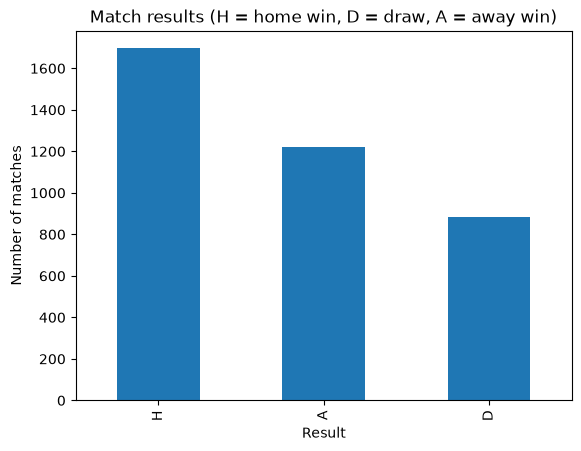

In [16]:
df['FTR'].value_counts().plot(kind='bar')  #use results of W/D/A and create a bar chart
plt.title('Match results (H = home win, D = draw, A = away win)') #title
plt.xlabel('Result') #naming results
plt.ylabel('Number of matches') #n matches
plt.show()

- Bar chart is a good option to analyse and compare the frequency that events use to happen in different categories 

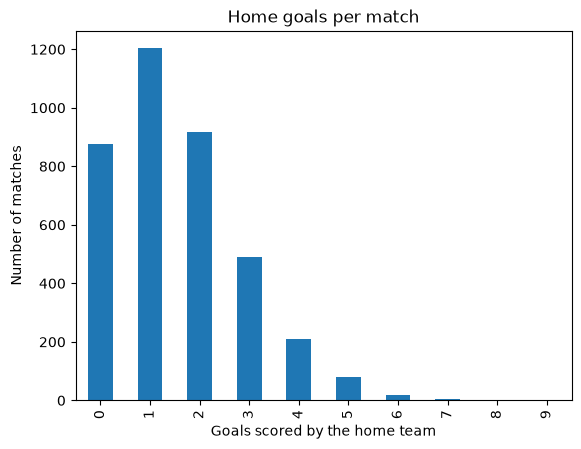

In [18]:
df['FTHG'].value_counts().sort_index().plot(kind='bar') #counting home goals - in a bar chart
plt.title('Home goals per match')
plt.xlabel('Goals scored by the home team')
plt.ylabel('Number of matches')
plt.show()
#Tail on the right because mean is bigger than median and mode. Median = 1, and the most common result is Moda = 1. 
#So all goals after 0 and 1 will make that tail on the right, and there's some, even 9, which is the biggest, but very rare.

- This bar chat show the frequency that happen certain number of goals. The highest bar is 1 so it is the mode and there is a tail to the right because it is not commun to happen matches with many goals.

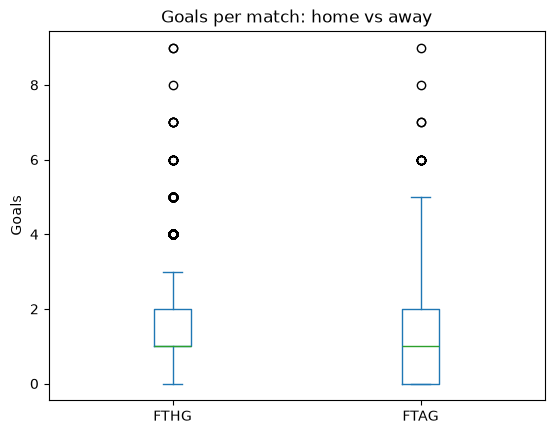

In [19]:
df[['FTHG', 'FTAG']].plot(kind='box')
plt.title('Goals per match: home vs away')
plt.ylabel('Goals')
plt.show()
#FTHG = MEDIAN 1 GOAL PER MATCH; HALF PART OF MATCHES IS FROM 1 TO 2 GOALS PER MATCH; LINE MAX IS THE VALUE THAT IS IN MAX 1,5 x IQR above The box = 0 TO 3.
#FTAG = MEDIAN 1 GOAL PER MATCH; HALF PART OF MATCHES IS FROM 0 TO 2 GOALS PER MATCH; LINE MAX IS VALUE 1,5 X IQR = 0 TO 5.
#The points after box is Outliers, that ones which is not common to happen. Like many goals per match.

- Boxplot is a good option because it shows the difference between home and aways goals in a way that is very easy to identify the outliers.
- While is very commun happen in FTHG 1 to 2 goals, the most commun in FTAG is 0 to 2. 

In [20]:
print(df['FTHG'].quantile([0.25, 0.50, 0.75, 0.90])) # Percentiles (25, 50, 75 and 90 percent)
#number of goals that don't pass 25%, 50%, 75% and 90% of the matches.(Teams use to make less goals than this value)
IntQuant = df['FTHG'].quantile(0.75) - df['FTHG'].quantile(0.25) # Interquartile range (IQR = Q3 - Q1)
print(IntQuant)

print((df['FTHG'] >= 4).mean() * 100) # Now check the Percentage of matches with 4 or more home goals
(df['FTHG'] >= 4).sum() #Number of matches had 4 goals or more

0.25    1.0
0.50    1.0
0.75    2.0
0.90    3.0
Name: FTHG, dtype: float64
1.0
8.289473684210526


np.int64(315)

- Q1 = 1, Median = 1, Q3 = 2, so IQR = 1, 315 matches have more than 4 home goals = 8,289%

In [21]:
print((df[['HS', 'AS', 'HF']] == 0).sum())

HS    1
AS    1
HF    2
dtype: int64


 - Check how many games had just 0 shots/fouls. If it were many matches, could be a problem. But in this case there are Very few games, so OK.

---------------------------------------------------------------------------------  PART 2  ------------------------------------------------------------------------------------